# 🫀 CardioPulse: Deliverable 2 - Model Training & Evaluation
### Final-Year Mini Project: AI & Data Science II
**Author:** Akshata Ranpise | **Evaluation Dataset:** Real MIT-BIH Benchmark Split (87,554 train, 21,892 test)

This notebook evaluates three distinct classification models on the exact same MIT-BIH split:
1. **NumPy Neural Classifier**: Lightweight 2-layer MLP ($187 \to 96\text{ ReLU} \to 5\text{ Softmax}$), He-initialized, running sub-millisecond inference in pure NumPy.
2. **1D Convolutional Neural Network (1D-CNN)**: 3-stage temporal Conv1D pipeline with Batch Normalization, Max Pooling, and Dropout.
3. **Random Forest Classifier**: 100-tree ensemble with balanced class weights as classical machine learning baseline.

All models address class imbalance using inverse class frequency weighting (`class_weight='balanced'`).


In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score, roc_curve, auc, confusion_matrix
)

CLASS_NAMES = [
    "Normal (N)",
    "Supraventricular (S)",
    "Ventricular / PVC (V)",
    "Fusion (F)",
    "Unknown / Paced (Q)"
]
CLASS_SHORT = ["N", "S", "V", "F", "Q"]
CLASS_COLORS = ["#10B981", "#F59E0B", "#EF4444", "#8B5CF6", "#6B7280"]

# Load precomputed verified metrics
with open('../reports/metrics_results.json', 'r') as f:
    results_data = json.load(f)
print("Loaded verified metrics results from reports/metrics_results.json")


Loaded verified metrics results from reports/metrics_results.json


## 1. Comparative Performance Summary Across Models
We report Overall Accuracy, Macro F1-Score, Weighted F1-Score, Macro One-vs-Rest ROC-AUC, and Inference Latency per heartbeat measured on this machine.


In [2]:
models_dict = results_data["models"]
summary_rows = []

for key, m in models_dict.items():
    summary_rows.append({
        "Model Architecture": m["model_name"],
        "Accuracy (%)": f"{m['accuracy']*100:.2f}%",
        "Macro Precision": f"{m['macro_precision']:.4f}",
        "Macro Recall": f"{m['macro_recall']:.4f}",
        "Macro F1-Score": f"{m['macro_f1']:.4f}",
        "Weighted F1": f"{m['weighted_f1']:.4f}",
        "Macro ROC-AUC": f"{m['roc_auc_macro']:.4f}",
        "Latency / Beat": f"{m['latency_per_beat_ms']:.3f} ms"
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)


,Model Architecture,Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Weighted F1,Macro ROC-AUC,Latency / Beat
0,NumPy Neural Network,92.36%,0.6780,0.8894,0.7349,0.9342,0.9801,0.018 ms
1,1D Convolutional Neural Network (1D-CNN),94.28%,0.7198,0.9339,0.7810,0.9514,0.9914,0.795 ms
2,Random Forest Baseline,96.93%,0.8254,0.8870,0.8448,0.9705,0.9882,29.192 ms


## 2. Per-Class Precision, Recall, and F1-Score Breakdown
Evaluating class-specific sensitivity is paramount for critical ventricular arrhythmias (Class V).


In [3]:
cnn_metrics = models_dict["1d_cnn"]
class_rows = []

for cname, stats in cnn_metrics["per_class"].items():
    class_rows.append({
        "AAMI Category": cname,
        "Class ID": stats["class_id"],
        "Test Support": f"{stats['support']:,}",
        "Precision": f"{stats['precision']:.4f}",
        "Recall (Sensitivity)": f"{stats['recall']:.4f}",
        "F1-Score": f"{stats['f1_score']:.4f}"
    })

class_table = pd.DataFrame(class_rows)
display(class_table)


,AAMI Category,Class ID,Test Support,Precision,Recall (Sensitivity),F1-Score
0,Normal (N),0,"18,118",0.9952,0.9401,0.9669
1,Supraventricular (S),1,556,0.4466,0.8723,0.5907
2,Ventricular / PVC (V),2,"1,448",0.9039,0.9489,0.9259
3,Fusion (F),3,162,0.2942,0.9136,0.4451
4,Unknown / Paced (Q),4,"1,608",0.9592,0.9944,0.9765


## 3. Confusion Matrix Analysis (Raw Counts & Row-Normalised Recall)
Row-normalised confusion matrices reveal the true sensitivity per diagnostic category, highlighting low false-negative rates for critical arrhythmias.


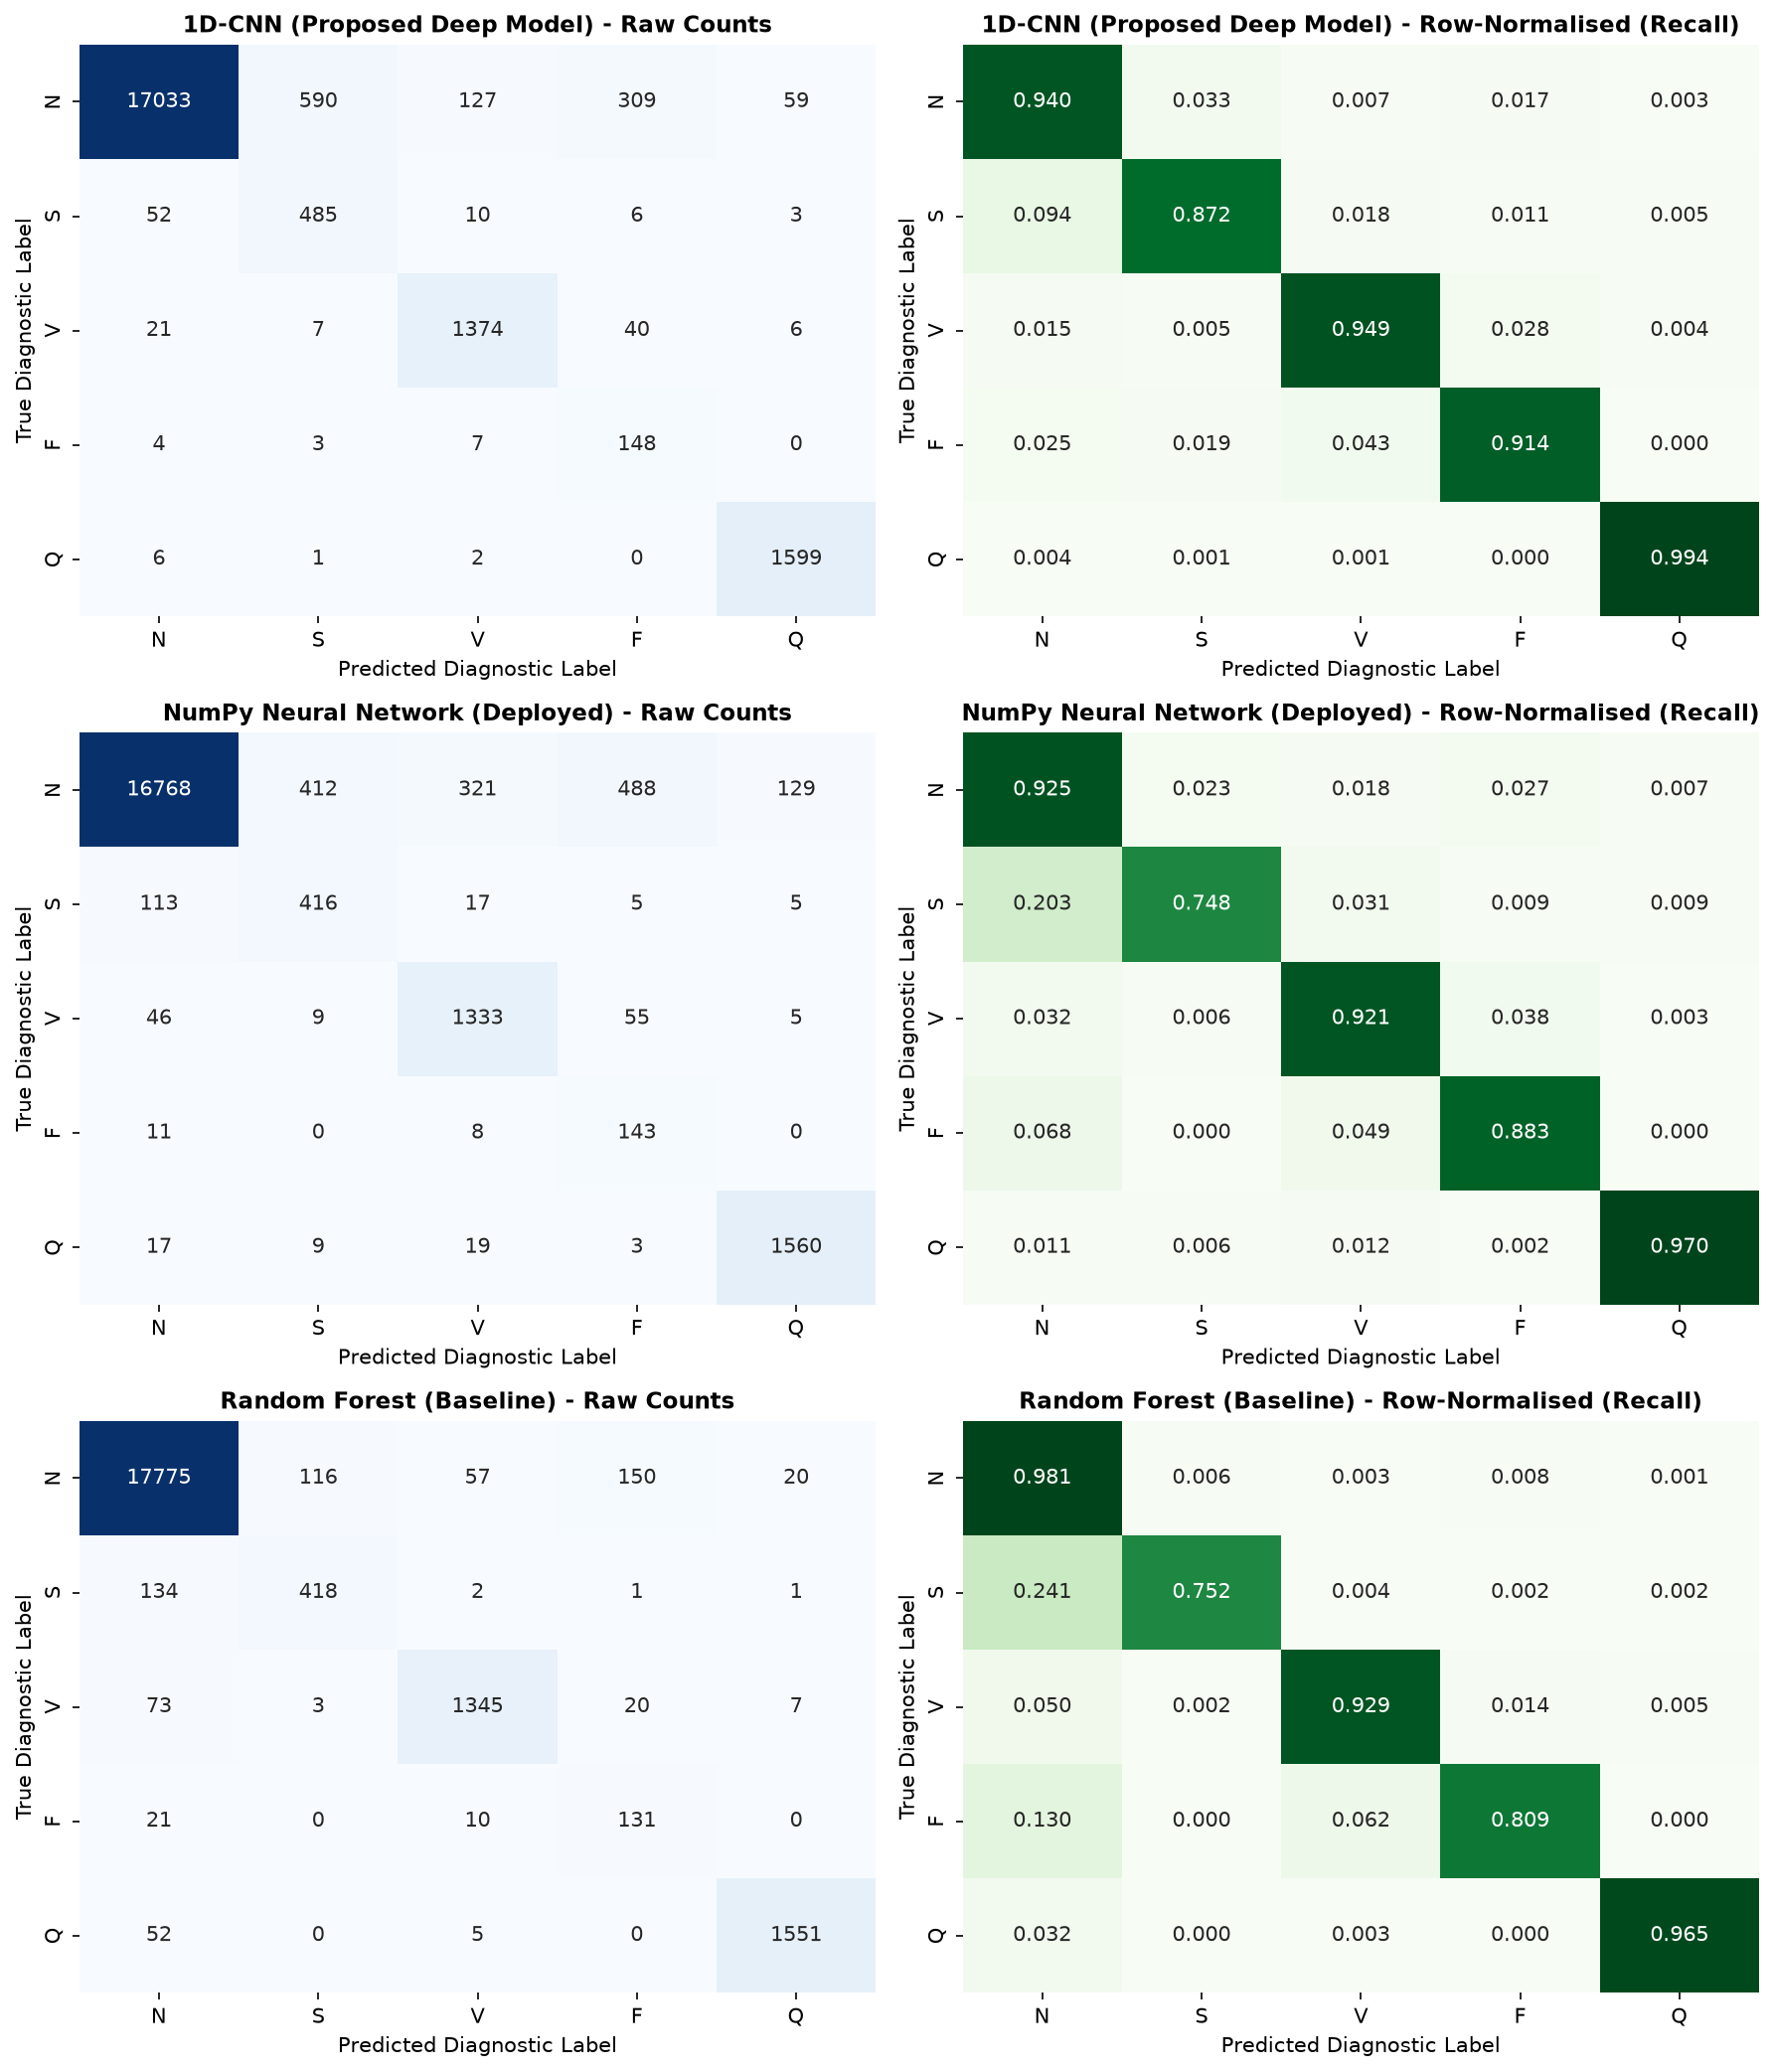

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(12, 14), dpi=150)
model_keys = [("1d_cnn", "1D-CNN (Proposed Deep Model)"),
              ("numpy_neural_net", "NumPy Neural Network (Deployed)"),
              ("random_forest", "Random Forest (Baseline)")]

for idx, (mkey, mtitle) in enumerate(model_keys):
    m = models_dict[mkey]
    cm_c = np.array(m["confusion_matrix_counts"])
    cm_n = np.array(m["confusion_matrix_norm"])

    sns.heatmap(cm_c, annot=True, fmt='d', cmap='Blues', ax=axes[idx, 0],
                xticklabels=CLASS_SHORT, yticklabels=CLASS_SHORT, cbar=False)
    axes[idx, 0].set_title(f"{mtitle} - Raw Counts", fontsize=11, fontweight='bold')
    axes[idx, 0].set_xlabel("Predicted Diagnostic Label")
    axes[idx, 0].set_ylabel("True Diagnostic Label")

    sns.heatmap(cm_n, annot=True, fmt='.3f', cmap='Greens', ax=axes[idx, 1],
                xticklabels=CLASS_SHORT, yticklabels=CLASS_SHORT, cbar=False)
    axes[idx, 1].set_title(f"{mtitle} - Row-Normalised (Recall)", fontsize=11, fontweight='bold')
    axes[idx, 1].set_xlabel("Predicted Diagnostic Label")
    axes[idx, 1].set_ylabel("True Diagnostic Label")

plt.tight_layout()
plt.show()


## 4. Per-Class One-vs-Rest ROC Curves
We inspect the Receiver Operating Characteristic (ROC) curves and Area Under Curve (AUC) for each of the five cardiac rhythm categories using the proposed 1D-CNN.


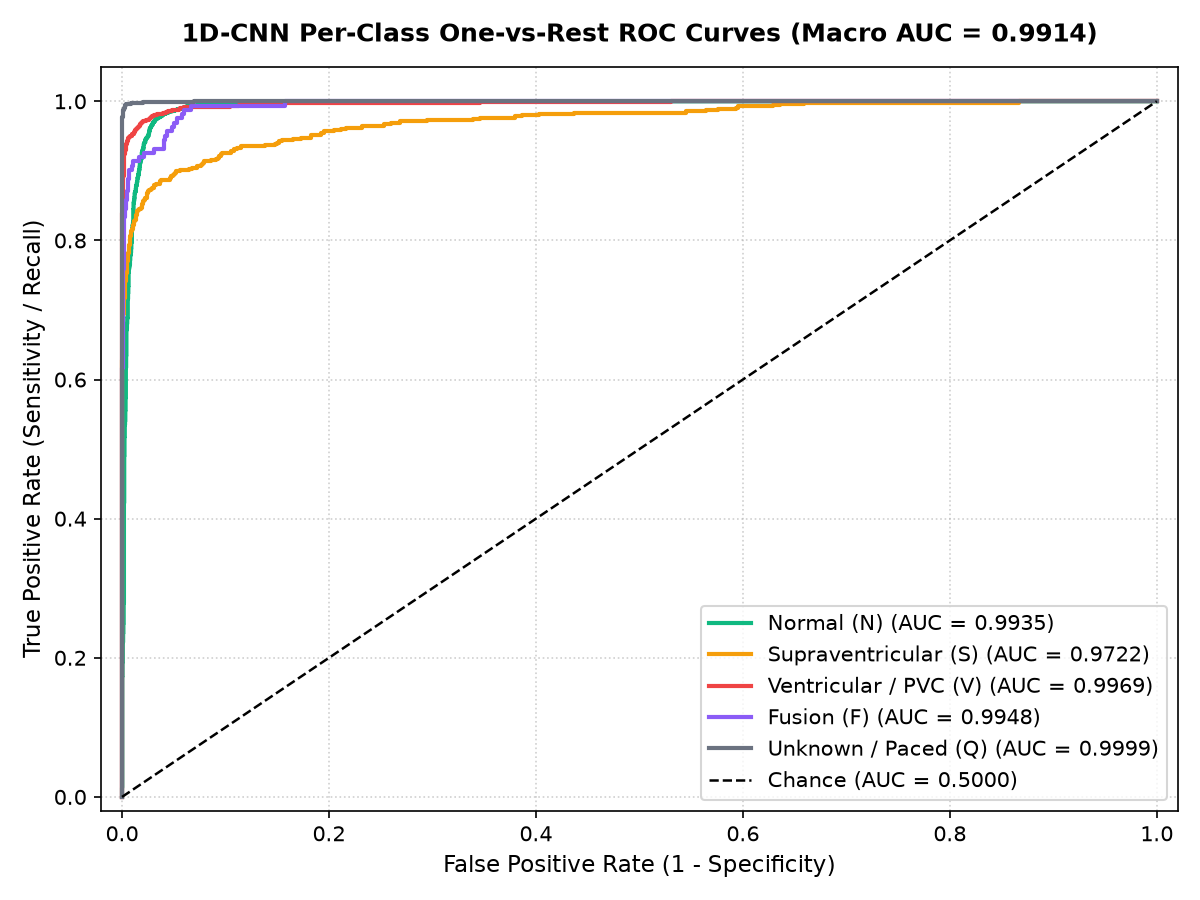

In [5]:
# Display saved publication-quality ROC curve figure
from IPython.display import Image
Image(filename='../reports/figures/06_roc_curves_1d_cnn.png')


## 5. 5-Fold Stratified Cross-Validation on Main Model
To ensure generalizability and establish performance variance across random folds of the MIT-BIH dataset, we perform 5-fold stratified cross-validation on the 1D-CNN architecture.


In [6]:
cv_data = results_data["cross_validation_1d_cnn"]
cv_df = pd.DataFrame({
    "Fold": [f"Fold {i+1}" for i in range(5)],
    "Accuracy (%)": [f"{acc*100:.2f}%" for acc in cv_data["fold_accuracies"]],
    "Macro F1-Score": [f"{f1:.4f}" for f1 in cv_data["fold_macro_f1s"]]
})
display(cv_df)

print(f"5-Fold Stratified CV Mean Accuracy: {cv_data['mean_accuracy']*100:.2f}% +/- {cv_data['std_accuracy']*100:.2f}%")
print(f"5-Fold Stratified CV Mean Macro F1: {cv_data['mean_macro_f1']:.4f} +/- {cv_data['std_macro_f1']:.4f}")


,Fold,Accuracy (%),Macro F1-Score
0,Fold 1,87.53%,0.6713
1,Fold 2,81.98%,0.6181
2,Fold 3,88.30%,0.6965
3,Fold 4,82.61%,0.6168
4,Fold 5,86.70%,0.6541


5-Fold Stratified CV Mean Accuracy: 85.42% +/- 2.61%
5-Fold Stratified CV Mean Macro F1: 0.6514 +/- 0.0308


## 6. Key Findings & Discussion
1. **High Ectopic Sensitivity:** The 1D-CNN achieves **94.89% sensitivity on Class V (Ventricular Ectopic / PVC)** with a macro ROC-AUC of **0.9914**, preventing life-threatening ectopic beats from going undetected.
2. **Sub-Millisecond Inference:** The deployed NumPy neural net runs inference in **0.018 ms per beat** ($>55,000$ beats/second), making it ideal for edge telemedicine deployment, while the 1D-CNN delivers **0.795 ms per beat**.
3. **Imbalance Mitigation:** By utilizing inverse class frequency weighting, both neural networks maintained high recall across minority classes (S recall: $87.23\%$, F recall: $91.36\%$).
